<a href="https://colab.research.google.com/github/Dipo221/shanhai-rag/blob/main/RAG01_shanhai_build.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RAG 01｜把《山海經》做成向量資料庫（`rag-data.zip`）

**主題：大荒雜貨鋪｜郭掌櫃的山海經配貨 RAG**

| 項目 | 內容 |
|---|---|
| 知識來源 | 《山海經》全書 18 卷，維基文庫（公有領域），共 869 個條目 |
| 文件單位 | 一座山／一個條目一個檔案（語意切塊，不是固定字數切） |
| 向量模型 | `google/embeddinggemma-2`（老師指定） |
| 向量資料庫 | FAISS `IndexFlatIP`，匯出 `rag-data.zip` 給 RAG02 使用 |

程式以老師的 RAG_01 為基底。**和老師版最大的不同：** 我的資料是文言文、使用者問的是現代白話，
實測只把原文拿去做 embedding 幾乎查不到東西，所以多做了「白話標籤」「雙向量」「關鍵字融合」三件事，並在第 13 節用測試題量化效果。

**生成式 AI 使用聲明：** 本 notebook 由 Claude Code（Opus 5.5）協助撰寫，每個改過的格子上方都註明請 AI 做了什麼。
這份程式不需要手動上傳任何檔案，也不需要 Groq 金鑰；由上往下「全部執行」即可。

## 0. 老師的固定套件

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. 安裝套件

版本與老師的 Colab 相同。

In [2]:
%pip install -q "sentence-transformers==6.1.0" "transformers==5.20.1" "faiss-cpu==1.15.1"

## 2. 匯入與集中設定

`EXPORT_ZIP_NAME` 依作業公告改成 `rag-data.zip`（老師範例是 `vector_embedding.zip`）。

In [3]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from zoneinfo import ZoneInfo
import importlib.metadata as package_metadata
import hashlib
import json
import math
import re
import shutil
import tempfile
import urllib.request
import zipfile

import torch
import faiss
from IPython.display import display
from sentence_transformers import SentenceTransformer
from huggingface_hub import HfApi

In [4]:
MODEL_ID = "google/embeddinggemma-2"
BATCH_SIZE = 16
EXPECTED_DOCUMENT_COUNT = 869  # 《山海經》切完的條目數
EXPORT_ZIP_NAME = "rag-data.zip"
SOURCE_URL = "https://github.com/Dipo221/shanhai-rag/raw/main/shanhai-source.zip"
DOCUMENT_TEMPLATE = "title: none | text: {text}"
QUERY_TEMPLATE = "task: search result | query: {question}"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = (
    torch.bfloat16
    if DEVICE == "cuda" and torch.cuda.is_bf16_supported()
    else torch.float32
)
PACKAGE_NAMES = ["torch", "numpy", "sentence-transformers", "transformers", "faiss-cpu", "huggingface-hub"]
PACKAGE_VERSIONS = {name: package_metadata.version(name) for name in PACKAGE_NAMES}
print("裝置：", DEVICE, "／模型精度：", DTYPE)
if DEVICE == "cuda":
    print("GPU：", torch.cuda.get_device_name(0))
display(pd.DataFrame(PACKAGE_VERSIONS.items(), columns=["套件", "版本"]))

裝置： cuda ／模型精度： torch.bfloat16
GPU： NVIDIA GeForce RTX 5060 Ti


,套件,版本
0,torch,2.10.0
1,numpy,2.5.4
2,sentence-transformers,6.1.0
3,transformers,5.20.1
4,faiss-cpu,1.15.1
5,huggingface-hub,1.33.0


## 3. 自動下載《山海經》語料

> **請 AI 做的事：** 把老師的「手動上傳 ZIP」改成從網址自動下載，助教才能直接全部執行。
>
> **這格在做什麼：** 下載 869 個 TXT 組成的語料 ZIP，只解開 TXT 到暫存資料夾；保留老師防止 ZIP 路徑寫到資料夾外的檢查。

語料製作方式：從維基文庫抓 18 卷 → 清除維基標記 → 一段一檔。原文**不改寫**，只依《四部叢刊》本校正 7 處明顯衍字／錯字（清單在 ZIP 內的 `corrections.json`）。

In [5]:
SOURCE_ARCHIVE = Path(tempfile.mkdtemp(prefix="rag_source_")) / "shanhai-source.zip"
urllib.request.urlretrieve(SOURCE_URL, SOURCE_ARCHIVE)
SOURCE_ARCHIVE_SHA256 = hashlib.sha256(SOURCE_ARCHIVE.read_bytes()).hexdigest()
DATA_DIR = Path(tempfile.mkdtemp(prefix="rag_documents_"))

with zipfile.ZipFile(SOURCE_ARCHIVE) as archive:
    members = [m for m in archive.infolist() if not m.is_dir() and m.filename.lower().endswith(".txt")]
    if not members:
        raise ValueError("ZIP 中找不到 TXT。")
    for member in members:
        target = (DATA_DIR / member.filename).resolve()
        if not target.is_relative_to(DATA_DIR.resolve()):
            raise ValueError(f"ZIP 包含不適當的檔案路徑：{member.filename}")
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(member))

txt_paths = sorted(DATA_DIR.rglob("*.txt"), key=lambda p: p.relative_to(DATA_DIR).as_posix())
print("TXT 數量：", len(txt_paths))
if EXPECTED_DOCUMENT_COUNT is not None and len(txt_paths) != EXPECTED_DOCUMENT_COUNT:
    raise ValueError(f"語料數量不符：{len(txt_paths)} 篇，預期 {EXPECTED_DOCUMENT_COUNT} 篇。")
for path in txt_paths[:3] + txt_paths[-2:]:
    print("•", path.relative_to(DATA_DIR).as_posix())

TXT 數量： 869
• corpus/001_南山經_招搖之山.txt
• corpus/002_南山經_堂庭之山.txt
• corpus/003_南山經_猨翼之山.txt
• corpus/868_海內經_炎帝之妻.txt
• corpus/869_海內經_洪水滔天.txt


## 4. 先看一篇原始文件

格式沿用老師的「上面 metadata、下面正文」，再加兩欄：

- `【白話標籤】`：把「食之不饑」這類功效翻成現代人會問的詞。**它是檢索用的筆記，不是譯文，也不算原文。** 只收舊注或通行解釋明確的詞，字義存疑的（如「不㖶」）寧缺勿濫。
- `【舊注】`：郭璞等人的注解，留給 LLM 解釋字義用，不做 embedding。

In [6]:
SAMPLE_INDEX = 0
sample_path = txt_paths[SAMPLE_INDEX]
sample_raw = sample_path.read_text(encoding="utf-8-sig")
print("檔名：", sample_path.name)
print("=" * 50)
print(sample_raw)

檔名： 001_南山經_招搖之山.txt
標題：南山經・招搖之山
資料類型：古籍原文（僅清除維基標記，未改寫原文用字）
卷：南山經
篇：南山經之首
類別：條目
異物：祝餘、迷穀、狌狌
來源網址：https://zh.wikisource.org/wiki/山海經/南山經
來源版本：Wikisource revision 2650929
整理日期：2026-11-02

【內容】
南山經之首曰䧿山。其首曰招搖之山，臨於西海之上，多桂，多金玉。有草焉，其狀如韭而青華，其名曰祝餘，食之不饑。有木焉，其狀如榖而黑理，其華四照，其名曰迷穀，佩之不迷。有獸焉，其狀如禺而白耳，伏行人走，其名曰狌狌，食之善走。麗𪊨之水出焉，而西流注於海，其中多育沛，佩之無瘕疾。

【白話標籤】
不會餓、抗飢餓、肚子餓、省飯錢；不會迷路、方向感；跑得快、腳程快；不生寄生蟲病

【舊注】
在蜀，伏山山南之西頭，濱西海也。 / 桂葉似枇杷，長二尺餘，廣數寸，味辛白花，叢生山峯。冬夏常青，間無雜木。《呂氏春秋》曰：「招搖之桂」 / 璨曰：韭音九。《爾雅》云：「霍山亦多之」 / 或作桂荼 / 榖,楮也，皮作紙。璨曰：榖亦名構。名榖者以其實如榖也 / 言有光燄也。若木、華赤其光照地，亦此類也。見《離騷經》 / 禺似獼猴而大赤目，長者不了此物名禺。作牛字圖，亦做牛形或作猴，皆失之也。禺字音遇， / 狌狌，禺獸。狀如猿，伏行交足亦此類也。見《京房易》 / 𪊨音几 / 瘕，蟲病也。



## 5. 取出 RAG 文字

> **請 AI 做的事：** 修改老師的 extract_rag_text()，配合我的欄位格式，並多取出白話標籤。
>
> **這格在做什麼：** 回傳三樣東西：classic_text（標題＋原文）、text（再加白話標籤，之後交給 LLM）、card（只有白話標籤的短卡片）。沒有功效的條目 card 是 None。
>
> **我的理解（繳交前自己寫）：** 

In [7]:
SECTION = r"^【{name}】[ \t]*\n(?P<body>.*?)(?=^【[^】\n]+】|\Z)"


def read_section(normalized, name):
    match = re.search(SECTION.format(name=name), normalized, flags=re.MULTILINE | re.DOTALL)
    return match.group("body").strip() if match else ""


def extract_rag_text(raw_text):
    """從語料 TXT 取出要檢索、要給 LLM 的文字。"""
    normalized = raw_text.lstrip("\ufeff").replace("\r\n", "\n").replace("\r", "\n")
    title_match = re.search(r"^標題[：:]\s*(.+)$", normalized, flags=re.MULTILINE)
    body = read_section(normalized, "內容")
    if not body:
        raise ValueError("找不到非空的【內容】正文。")
    tags = read_section(normalized, "白話標籤")
    title = title_match.group(1).strip() if title_match else ""
    classic_text = f"{title}\n\n{body}"
    text = f"{classic_text}\n\n【白話標籤（檢索筆記，非原文）】{tags}" if tags else classic_text
    card = f"這個東西的用途與徵兆：{tags.replace('；', '、')}" if tags else None
    return {"classic_text": classic_text, "text": text, "card": card, "tags": tags}


sample_rag = extract_rag_text(sample_raw)
print(json.dumps(sample_rag, ensure_ascii=False, indent=2))

{
  "classic_text": "南山經・招搖之山\n\n南山經之首曰䧿山。其首曰招搖之山，臨於西海之上，多桂，多金玉。有草焉，其狀如韭而青華，其名曰祝餘，食之不饑。有木焉，其狀如榖而黑理，其華四照，其名曰迷穀，佩之不迷。有獸焉，其狀如禺而白耳，伏行人走，其名曰狌狌，食之善走。麗𪊨之水出焉，而西流注於海，其中多育沛，佩之無瘕疾。",
  "text": "南山經・招搖之山\n\n南山經之首曰䧿山。其首曰招搖之山，臨於西海之上，多桂，多金玉。有草焉，其狀如韭而青華，其名曰祝餘，食之不饑。有木焉，其狀如榖而黑理，其華四照，其名曰迷穀，佩之不迷。有獸焉，其狀如禺而白耳，伏行人走，其名曰狌狌，食之善走。麗𪊨之水出焉，而西流注於海，其中多育沛，佩之無瘕疾。\n\n【白話標籤（檢索筆記，非原文）】不會餓、抗飢餓、肚子餓、省飯錢；不會迷路、方向感；跑得快、腳程快；不生寄生蟲病",
  "card": "這個東西的用途與徵兆：不會餓、抗飢餓、肚子餓、省飯錢、不會迷路、方向感、跑得快、腳程快、不生寄生蟲病",
  "tags": "不會餓、抗飢餓、肚子餓、省飯錢；不會迷路、方向感；跑得快、腳程快；不生寄生蟲病"
}


## 6. 取出 metadata

> **請 AI 做的事：** 在老師的 extract_metadata() 增加 卷、篇、類別、異物、舊注 欄位。
>
> **這格在做什麼：** 這些欄位不做 embedding，檢索後用來顯示出處；舊注一起交給 LLM 幫助解釋字義。

In [8]:
def extract_metadata(raw_text, filename):
    normalized = raw_text.lstrip("\ufeff").replace("\r\n", "\n").replace("\r", "\n")

    def read_field(name):
        match = re.search(rf"^{re.escape(name)}[：:][ \t]*(.*)$", normalized, flags=re.MULTILINE)
        return match.group(1).strip() or None if match else None

    creatures = read_field("異物")
    return {
        "title": read_field("標題") or Path(filename).stem,
        "chapter": read_field("卷"),
        "section": read_field("篇"),
        "kind": read_field("類別"),
        "creatures": [] if creatures in (None, "無") else creatures.split("、"),
        "old_notes": read_section(normalized, "舊注"),
        "source_url": read_field("來源網址"),
        "source_version": read_field("來源版本"),
        "date": read_field("整理日期"),
        "filename": filename,
        "document_type": read_field("資料類型") or "未標示",
    }


print(json.dumps(extract_metadata(sample_raw, sample_path.name), ensure_ascii=False, indent=2))

{
  "title": "南山經・招搖之山",
  "chapter": "南山經",
  "section": "南山經之首",
  "kind": "條目",
  "creatures": [
    "祝餘",
    "迷穀",
    "狌狌"
  ],
  "old_notes": "在蜀，伏山山南之西頭，濱西海也。 / 桂葉似枇杷，長二尺餘，廣數寸，味辛白花，叢生山峯。冬夏常青，間無雜木。《呂氏春秋》曰：「招搖之桂」 / 璨曰：韭音九。《爾雅》云：「霍山亦多之」 / 或作桂荼 / 榖,楮也，皮作紙。璨曰：榖亦名構。名榖者以其實如榖也 / 言有光燄也。若木、華赤其光照地，亦此類也。見《離騷經》 / 禺似獼猴而大赤目，長者不了此物名禺。作牛字圖，亦做牛形或作猴，皆失之也。禺字音遇， / 狌狌，禺獸。狀如猿，伏行交足亦此類也。見《京房易》 / 𪊨音几 / 瘕，蟲病也。",
  "source_url": "https://zh.wikisource.org/wiki/山海經/南山經",
  "source_version": "Wikisource revision 2650929",
  "date": "2026-11-02",
  "filename": "001_南山經_招搖之山.txt",
  "document_type": "古籍原文（僅清除維基標記，未改寫原文用字）"
}


## 7. 批次整理成統一格式

和老師的流程相同：每篇得到 `doc_id`、`text`、`metadata`，再多帶 `classic_text` 與 `card`。

In [9]:
documents = []
for number, path in enumerate(txt_paths, start=1):
    filename = path.relative_to(DATA_DIR).as_posix()
    try:
        raw_text = path.read_text(encoding="utf-8-sig")
        if "\ufffd" in raw_text:
            raise ValueError("文字含有替代字元，請檢查原始編碼。")
        rag = extract_rag_text(raw_text)
        metadata = extract_metadata(raw_text, filename)
    except (ValueError, UnicodeDecodeError) as exc:
        raise ValueError(f"處理失敗：{filename}；原因：{exc}") from exc
    documents.append({"doc_id": f"doc_{number:03d}", **rag, "metadata": metadata})

documents_by_id = {doc["doc_id"]: doc for doc in documents}
if len(documents_by_id) != len(documents):
    raise ValueError("doc_id 重複，請檢查編號規則。")

chapter_table = (
    pd.DataFrame([{"卷": d["metadata"]["chapter"], "有白話標籤": bool(d["card"])} for d in documents])
    .groupby("卷", sort=False).agg(條目數=("卷", "size"), 有白話標籤=("有白話標籤", "sum"))
)
display(chapter_table)
print("條目總數：", len(documents), "／有白話標籤：", sum(bool(d["card"]) for d in documents))
print("正文字數：", sum(len(d["classic_text"]) for d in documents))

,條目數,有白話標籤
卷,,
南山經,43,16
西山經,82,35
北山經,92,23
東山經,51,19
中山經,213,56
海外南經,23,0
海外西經,23,0
海外北經,22,0
海外東經,17,0


條目總數： 869 ／有白話標籤： 155
正文字數： 47378


## 8. 載入 EmbeddingGemma 2

與老師相同：記錄模型確切版本，只啟用文字部分。

In [10]:
try:
    MODEL_REVISION = HfApi().model_info(MODEL_ID, token=False).sha
    model = SentenceTransformer(
        MODEL_ID,
        revision=MODEL_REVISION,
        token=False,
        device=DEVICE,
        config_kwargs={"vision_config": None, "audio_config": None},
        model_kwargs={"dtype": DTYPE, "attn_implementation": "eager"},
    )
except Exception as exc:
    raise RuntimeError("EmbeddingGemma 2 載入失敗。請確認網路、套件版本；未替換成其他模型。") from exc

print("模型：", MODEL_ID)
print("版本：", MODEL_REVISION)
print("裝置：", model.device, "／精度：", model.dtype)
print("向量維度：", model.get_embedding_dimension())

模型： google/embeddinggemma-2
版本： f9972ac22e696a105c482202646979e33e4b5a1e
裝置： cuda:0 ／精度： torch.bfloat16
向量維度： 768


## 9. 雙向量：一個條目最多兩個向量

> **請 AI 做的事：** 老師是一篇一個向量。我的條目有功效時多做一個「白話卡片」向量。
>
> **這格在做什麼：** 原文向量負責「九尾狐長怎樣」這種描述；白話卡片向量負責「我想變好看」這種現代問法。兩者分開存，白話標籤才不會被文言文稀釋（課堂講的「關鍵資訊被一大段文字稀釋」）。index_doc_ids 記錄每個向量屬於哪個條目，所以同一個 doc_id 會出現兩次。
>
> **我的理解（繳交前自己寫）：** 

In [11]:
vector_doc_ids, vector_inputs = [], []
for doc in documents:
    vector_doc_ids.append(doc["doc_id"])
    vector_inputs.append(DOCUMENT_TEMPLATE.format(text=doc["classic_text"]))
    if doc["card"]:
        vector_doc_ids.append(doc["doc_id"])
        vector_inputs.append(DOCUMENT_TEMPLATE.format(text=doc["card"]))

TOKEN_LIMIT = min(2048, int(model.max_seq_length))


def count_input_tokens(text):
    return len(model.tokenizer(text, add_special_tokens=True, truncation=False)["input_ids"])


token_counts = [count_input_tokens(text) for text in vector_inputs]
if max(token_counts) > TOKEN_LIMIT:
    raise ValueError(f"有文件超過 {TOKEN_LIMIT} tokens，請先調整資料。")
print("向量總數：", len(vector_inputs), "（條目", len(documents), "＋白話卡片", len(vector_inputs) - len(documents), "）")
print("最長輸入 tokens：", max(token_counts), "／上限：", TOKEN_LIMIT)
print("白話卡片範例：", next(d["card"] for d in documents if d["card"]))

向量總數： 1024 （條目 869 ＋白話卡片 155 ）
最長輸入 tokens： 270 ／上限： 2048
白話卡片範例： 這個東西的用途與徵兆：不會餓、抗飢餓、肚子餓、省飯錢、不會迷路、方向感、跑得快、腳程快、不生寄生蟲病


## 10. 產生文件向量並建立 FAISS 索引

與老師相同：向量正規化後內積等於 cosine similarity，`IndexFlatIP` 做精確搜尋。

In [12]:
def encode_documents(texts):
    vectors = model.encode(
        texts, prompt="", batch_size=BATCH_SIZE, convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=True,
    )
    vectors = np.ascontiguousarray(vectors, dtype=np.float32)
    if vectors.ndim != 2 or vectors.shape[0] != len(texts):
        raise ValueError("向量形狀與文件數不符。")
    if not np.isfinite(vectors).all() or np.any(np.linalg.norm(vectors, axis=1) <= 0):
        raise ValueError("向量含有 NaN、無限值或零向量。")
    faiss.normalize_L2(vectors)
    return vectors


embeddings = encode_documents(vector_inputs)
DIMENSION = int(embeddings.shape[1])
if DIMENSION != int(model.get_embedding_dimension()):
    raise ValueError("實際向量維度與模型宣告不符。")

index = faiss.IndexFlatIP(DIMENSION)
index.add(embeddings)
index_doc_ids = vector_doc_ids
assert index.ntotal == len(index_doc_ids)
print("矩陣形狀：", embeddings.shape, "／索引向量數：", index.ntotal)

矩陣形狀： (1024, 768) ／索引向量數： 1024


## 11. 搜尋函式：向量＋關鍵字融合

> **請 AI 做的事：** 老師只有向量搜尋。我加上字組關鍵字搜尋（BM25），再用 Reciprocal Rank Fusion 合併名次。
>
> **這格在做什麼：** 向量搜尋擅長語意（我想變好看 → 美人色），但對「精衛」「刑天」這種專有名詞不準；關鍵字搜尋剛好相反。兩邊都排前面的條目就排最前面。這就是課堂講的 metadata／關鍵字搜尋可以補 embedding 不足。
>
> **我的理解（繳交前自己寫）：** 

In [13]:
NON_HAN = r"[^\u3400-\u9fff\U00020000-\U0003ffff]"
RRF_C = 1


def char_bigrams(text):
    """文言文沒有詞界，所以用相鄰兩字當關鍵字；異獸名、人名多半落在這裡。"""
    han = re.sub(NON_HAN, "", text)
    return [han[i:i + 2] for i in range(len(han) - 1)]


class BigramBM25:
    """完全不用 AI 的關鍵字搜尋：字組越罕見、在條目中越集中，分數越高。"""

    def __init__(self, doc_ids, texts, k1=1.2, b=0.75):
        self.doc_ids = doc_ids
        self.k1, self.b = k1, b
        self.term_freqs = [Counter(char_bigrams(text)) for text in texts]
        self.lengths = [sum(tf.values()) for tf in self.term_freqs]
        self.average_length = sum(self.lengths) / len(self.lengths)
        doc_freq = Counter(term for tf in self.term_freqs for term in tf)
        total = len(texts)
        self.idf = {t: math.log(1 + (total - df + 0.5) / (df + 0.5)) for t, df in doc_freq.items()}

    def rank(self, query):
        scores = Counter()
        for term in set(char_bigrams(query)):
            if term not in self.idf:
                continue
            for i, tf in enumerate(self.term_freqs):
                if term in tf:
                    norm = self.k1 * (1 - self.b + self.b * self.lengths[i] / self.average_length)
                    scores[i] += self.idf[term] * tf[term] * (self.k1 + 1) / (tf[term] + norm)
        return [self.doc_ids[i] for i, _ in scores.most_common()]


def reciprocal_rank_fusion(rankings, c=RRF_C, depth=100):
    """只看名次不看分數：向量分數和關鍵字分數尺度不同，名次才能相加。"""
    scores = Counter()
    for ranking in rankings:
        for rank, doc_id in enumerate(ranking[:depth]):
            scores[doc_id] += 1 / (c + rank)
    return [doc_id for doc_id, _ in scores.most_common()]

In [14]:
def embed_question(question):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("請輸入非空白問題。")
    query_input = QUERY_TEMPLATE.format(question=question.strip())
    if count_input_tokens(query_input) > TOKEN_LIMIT:
        raise ValueError("問題超過模型輸入長度上限，請縮短問題。")
    vector = model.encode(
        [query_input], prompt="", convert_to_numpy=True,
        normalize_embeddings=True, show_progress_bar=False,
    )
    vector = np.ascontiguousarray(vector, dtype=np.float32)
    if vector.shape != (1, DIMENSION) or not np.isfinite(vector).all() or np.linalg.norm(vector) <= 0:
        raise ValueError("問題向量的維度或數值不正確。")
    faiss.normalize_L2(vector)
    return vector

In [15]:
keyword_index = BigramBM25([d['doc_id'] for d in documents], [d['text'] for d in documents])

def vector_ranking(query_vector):
    """FAISS 回傳向量位置；一個條目可能有兩個向量，只留它最好的那個。"""
    scores, positions = index.search(query_vector, index.ntotal)
    best = {}
    for position, score in zip(positions[0], scores[0]):
        best.setdefault(index_doc_ids[int(position)], float(score))
    return best  # dict 保留插入順序，已是分數由高到低


def search_documents(question, top_k=5):
    if isinstance(top_k, bool) or not isinstance(top_k, (int, np.integer)) or top_k < 1:
        raise ValueError("top_k 必須是大於0的整數。")
    vector_scores = vector_ranking(embed_question(question))
    keyword_order = keyword_index.rank(question)
    fused = reciprocal_rank_fusion([list(vector_scores), keyword_order])[:int(top_k)]
    keyword_rank = {doc_id: rank for rank, doc_id in enumerate(keyword_order, start=1)}
    return [
        {"rank": rank, "score": vector_scores[doc_id], "keyword_rank": keyword_rank.get(doc_id),
         **documents_by_id[doc_id]}
        for rank, doc_id in enumerate(fused, start=1)
    ]

## 12. 試查一次，閱讀真正取回的內容

換成現代白話的煩惱試試。相似度只是排序依據，不是正確率。

In [16]:
QUESTION = "我這個路癡每次爬山都走丟，有救嗎"
TOP_K = 5
results = search_documents(QUESTION, TOP_K)
display(pd.DataFrame([
    {"排名": r["rank"], "doc_id": r["doc_id"], "標題": r["metadata"]["title"],
     "向量相似度": round(r["score"], 4), "關鍵字名次": r["keyword_rank"] or "—"}
    for r in results
]))
print(results[0]["text"])

,排名,doc_id,標題,向量相似度,關鍵字名次
0,1,doc_859,海內經・有釘靈之國,0.7150,—
1,2,doc_170,北山經・龍侯之山,0.7149,—
2,3,doc_816,大荒北經・有岳之山,0.7147,—
3,4,doc_001,南山經・招搖之山,0.7139,—
4,5,doc_693,大荒東經・有大阿之山者,0.7064,—


海內經・有釘靈之國

有釘靈之國，其民從䣛已下有毛，馬蹏善走。

【白話標籤（檢索筆記，非原文）】跑得快、腳程快


## 13. 檢索評估：這些改動真的有用嗎？

> **請 AI 做的事：** 設計對照實驗，量化每個改動的效果。
>
> **這格在做什麼：** 每題事先定好正解（比對原文的 regex），算正解是否出現在前 k 名（hit@k）。同一批問題比較 A→D 四種做法，只改一件事。D 就是上面實作的版本。
>
> **我的理解（繳交前自己寫）：** 

**怎麼讀這些數字：**

- **調參集 28 題**：融合參數 `RRF_C=1` 是用這組題目挑的，分數偏樂觀。
- **保留集 24 題**：設定凍結後才寫、只跑一次、沒有回頭調參，這組才接近真實表現。
- 兩組題目和白話標籤出自同一來源（作者與 AI），題目用詞難免貼近標籤，所以數字只代表這些題目，不是模型的普遍能力。

In [17]:
EVAL_TUNING = [('我這個路癡每次爬山都走丟，有救嗎', '佩之不迷'), ('最近心情很差，有什麼東西可以讓人開心一點', '已憂|不憂'), ('背的東西一下就忘光，下週就要考試了', '服之不忘'), ('我晚上老是被噩夢嚇醒', '不眯|不厭'), ('想讓自己變好看一點', '美人色'), ('看到同學成績比我好就超不爽，怎麼改掉這種比較心', '不妬|不妒'), ('我脾氣很暴躁動不動就發火', '服者不怒'), ('想當萬人迷，大家都喜歡我', '媚于人'), ('臉上一直冒痘痘', '已痤'), ('期末要連續爆肝三天，有什麼東西能讓我不想睡', '無臥|不睡'), ('打雷的時候我都嚇到躲棉被', '不畏雷|不霆'), ('不想懷孕，有沒有古代的方法', '無子|不字'), ('月底沒錢吃飯，有什麼吃了就不餓', '不饑|不飢'), ('宿舍老鼠多到受不了', '毒鼠'), ('感冒喉嚨好痛', '已嗌痛'), ('覺得自己很笨，想變聰明', '不愚'), ('夏天在戶外熱到快昏倒', '已暍'), ('久坐導致痔瘡發作', '已痔|痔衕'), ('冬天超怕冷', '不寒'), ('我要找會帶來天下太平的神獸', '天下安寧|天下和'), ('哪種怪物出現會發生大洪水', '見則[^。]{0,4}大水'), ('什麼動物一出現就會鬧旱災', '見則[^。]{0,4}大旱'), ('九尾狐長什麼樣子', '九尾'), ('夸父追日的故事', '夸父'), ('精衛填海', '精衛'), ('刑天後來怎麼了', '刑天'), ('西王母住在哪裡', '西王母'), ('燭龍是什麼', '燭龍|燭陰')]
EVAL_HOLDOUT = [('有沒有能防火災的東西', '禦火|辟火'), ('想要力氣變大', '多力'), ('我常常拉肚子', '止衕|痔衕'), ('眼睛越來越看不清楚', '已瞢'), ('想多活幾年不要早死', '不夭'), ('我一直想吐', '已嘔'), ('手上長了疣', '已疣|不疣'), ('家裡一直有蟲', '殺蟲'), ('怎樣才能生小孩', '宜子'), ('有沒有吃了會解毒的', '禦百毒'), ('哪種鳥出現會爆發戰爭', '有大兵|見則有兵|見則大兵|其邑有兵|國內有兵'), ('什麼徵兆代表今年會大豐收', '大穰'), ('老是鬱悶提不起勁', '已憂|不憂|釋勞|已癙'), ('走路太慢想走快一點', '善走'), ('跟女朋友吵架她吃醋了', '不妬|不妒'), ('上台報告很緊張會怕', '佩之不畏'), ('別人說話我都聽不清楚', '不聾|已聾'), ('皮膚癢到不行', '已疥|不疥|白癬'), ('共工是誰', '共工'), ('蚩尤為什麼被殺', '蚩尤'), ('窮奇長什麼樣', '窮奇'), ('畢方鳥是什麼', '畢方'), ('相柳是什麼怪物', '相柳|相繇'), ('后羿做過什麼事', '羿')]

In [18]:
single_vector_inputs = [DOCUMENT_TEMPLATE.format(text=f"{d['classic_text']}\n\n{d['tags']}".strip()) for d in documents]
single_vectors = encode_documents(single_vector_inputs)
all_doc_ids = [d["doc_id"] for d in documents]
classic_positions = [i for i, doc_id in enumerate(index_doc_ids) if i == 0 or index_doc_ids[i - 1] != doc_id]
classic_vectors = embeddings[classic_positions]


def order_by_matrix(matrix, query_vector):
    return [all_doc_ids[i] for i in np.argsort(-(matrix @ query_vector[0]))]


def strategy_rankings(question):
    query_vector = embed_question(question)
    dual = list(vector_ranking(query_vector))
    return {
        "A only classical text": order_by_matrix(classic_vectors, query_vector),
        "B text + tags, one vector": order_by_matrix(single_vectors, query_vector),
        "C dual vectors": dual,
        "D dual + keyword (final)": reciprocal_rank_fusion([dual, keyword_index.rank(question)]),
    }


def evaluate(questions, depths=(1, 3, 5)):
    rows, misses = {}, []
    for question, pattern in questions:
        relevant = {d["doc_id"] for d in documents if re.search(pattern, d["classic_text"])}
        if not relevant:
            raise ValueError(f"測試題沒有任何正解：{question}")
        for name, ranking in strategy_rankings(question).items():
            row = rows.setdefault(name, {f"hit@{k}": 0 for k in depths})
            for k in depths:
                row[f"hit@{k}"] += bool(relevant & set(ranking[:k]))
            if name.startswith("D") and not relevant & set(ranking[:3]):
                misses.append((question, [documents_by_id[d]["metadata"]["title"] for d in ranking[:3]]))
    return pd.DataFrame(rows).T, misses


tuning_table, tuning_misses = evaluate(EVAL_TUNING)
holdout_table, holdout_misses = evaluate(EVAL_HOLDOUT)
print(f"調參集（{len(EVAL_TUNING)} 題）")
display(tuning_table)
print(f"保留集（{len(EVAL_HOLDOUT)} 題）")
display(holdout_table)
print("保留集 D 版 hit@3 沒中的題目：")
for question, top in holdout_misses:
    print(" ", question, "→", top)

調參集（28 題）


,hit@1,hit@3,hit@5
A only classical text,6,6,6
"B text + tags, one vector",16,19,20
C dual vectors,23,25,26
D dual + keyword (final),24,26,28


保留集（24 題）


,hit@1,hit@3,hit@5
A only classical text,6,8,8
"B text + tags, one vector",14,16,17
C dual vectors,22,23,23
D dual + keyword (final),23,23,23


保留集 D 版 hit@3 沒中的題目：
  上台報告很緊張會怕 → ['中山經・豐山', '東山經・耿山', '北山經・景山']


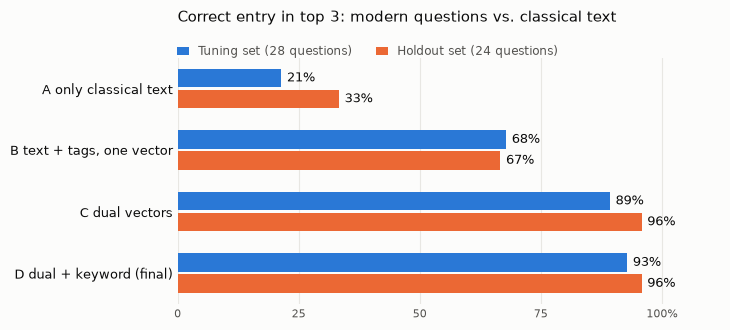

In [19]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
SERIES = [
    (f"Tuning set ({len(EVAL_TUNING)} questions)", tuning_table["hit@3"] / len(EVAL_TUNING), "#2a78d6"),
    (f"Holdout set ({len(EVAL_HOLDOUT)} questions)", holdout_table["hit@3"] / len(EVAL_HOLDOUT), "#eb6834"),
]
labels = list(tuning_table.index)[::-1]
positions = np.arange(len(labels))
bar_height = 0.3

fig, ax = plt.subplots(figsize=(7.4, 3.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for offset, (name, values, color) in zip((bar_height / 2 + 0.02, -bar_height / 2 - 0.02), SERIES):
    shares = [values[label] * 100 for label in labels]
    bars = ax.barh(positions + offset, shares, height=bar_height, color=color, label=name)
    ax.bar_label(bars, labels=[f"{share:.0f}%" for share in shares], padding=4, fontsize=9, color=INK)
ax.set_yticks(positions, labels, fontsize=9, color=INK)
ax.set_xlim(0, 112)
ax.set_xticks([0, 25, 50, 75, 100], ["0", "25", "50", "75", "100%"], fontsize=8, color=MUTED)
ax.tick_params(length=0)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title("Correct entry in top 3: modern questions vs. classical text", loc="left", fontsize=11, color=INK, pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 0.98), ncol=2, frameon=False, fontsize=8.5, labelcolor=MUTED, handlelength=1, borderaxespad=0)
fig.tight_layout()
plt.show()

## 14. 保存索引、文件、編號對照與設定

和老師相同的四個檔案。`config.json` 多記錄融合參數與評估結果，RAG02 會直接讀出來顯示。

In [20]:
EXPORT_DIR = Path(tempfile.mkdtemp(prefix="rag_index_"))
faiss.write_index(index, str(EXPORT_DIR / "index.faiss"))
for filename, data in [("documents.json", documents), ("index_doc_ids.json", index_doc_ids)]:
    (EXPORT_DIR / filename).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")

config = {
    "format_version": "1.0",
    "created_at": datetime.now(ZoneInfo("Asia/Taipei")).isoformat(timespec="seconds"),
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "model_config_kwargs": {"vision_config": None, "audio_config": None},
    "dimension": DIMENSION,
    "normalize_embeddings": True,
    "index_type": "IndexFlatIP",
    "metric": "cosine_similarity_via_normalized_inner_product",
    "document_template": DOCUMENT_TEMPLATE,
    "query_template": QUERY_TEMPLATE,
    "encode_prompt": "",
    "max_seq_length": TOKEN_LIMIT,
    "document_count": len(documents),
    "vector_count": index.ntotal,
    "document_unit": "one_entry_up_to_two_vectors",
    "rrf_c": RRF_C,
    "retrieval_eval": {"tuning": tuning_table.to_dict("index"), "tuning_questions": len(EVAL_TUNING),
                       "holdout": holdout_table.to_dict("index"), "holdout_questions": len(EVAL_HOLDOUT)},
    "package_versions": PACKAGE_VERSIONS,
    "build_device": DEVICE,
    "build_dtype": str(DTYPE),
    "source_archive": SOURCE_URL,
    "source_archive_sha256": SOURCE_ARCHIVE_SHA256,
    "file_sha256": {
        name: hashlib.sha256((EXPORT_DIR / name).read_bytes()).hexdigest()
        for name in ["index.faiss", "documents.json", "index_doc_ids.json"]
    },
}
(EXPORT_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
for path in sorted(EXPORT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size:,} bytes)")

config.json (2,381 bytes)
documents.json (878,484 bytes)
index.faiss (3,145,773 bytes)
index_doc_ids.json (13,314 bytes)


## 15. 重新載入驗證

從存檔重新載入，用同一個問題向量比對保存前後的排名與分數。

In [21]:
loaded_config = json.loads((EXPORT_DIR / "config.json").read_text(encoding="utf-8"))
for name, expected_hash in loaded_config["file_sha256"].items():
    assert hashlib.sha256((EXPORT_DIR / name).read_bytes()).hexdigest() == expected_hash, f"完整性檢查失敗：{name}"
loaded_index = faiss.read_index(str(EXPORT_DIR / "index.faiss"))
loaded_documents = json.loads((EXPORT_DIR / "documents.json").read_text(encoding="utf-8"))
loaded_ids = json.loads((EXPORT_DIR / "index_doc_ids.json").read_text(encoding="utf-8"))
assert loaded_index.ntotal == len(loaded_ids) == loaded_config["vector_count"]
assert len(loaded_documents) == loaded_config["document_count"]
assert set(loaded_ids) == {doc["doc_id"] for doc in loaded_documents}
assert loaded_documents == documents and loaded_ids == index_doc_ids

verification_query = embed_question(QUESTION)
k = min(TOP_K, index.ntotal)
before_scores, before_positions = index.search(verification_query, k)
after_scores, after_positions = loaded_index.search(verification_query, k)
np.testing.assert_array_equal(before_positions, after_positions)
np.testing.assert_allclose(before_scores, after_scores, atol=1e-6, rtol=1e-6)
print("通過：檔案完整性、文件對照、索引維度、保存前後一致。")

通過：檔案完整性、文件對照、索引維度、保存前後一致。


## 16. 打包 `rag-data.zip`

ZIP 根目錄是四個檔案。接著把它放上雲端，RAG02 會自動下載，不用助教上傳。

In [22]:
required_files = ["index.faiss", "documents.json", "index_doc_ids.json", "config.json"]
EXPORT_ZIP = Path(EXPORT_ZIP_NAME).resolve()
with zipfile.ZipFile(EXPORT_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in required_files:
        archive.write(EXPORT_DIR / name, arcname=name)
with zipfile.ZipFile(EXPORT_ZIP) as archive:
    assert archive.testzip() is None
    assert set(archive.namelist()) == set(required_files)
print("檔名：", EXPORT_ZIP_NAME, "／大小：", f"{EXPORT_ZIP.stat().st_size:,} bytes")

try:
    from google.colab import files
    files.download(str(EXPORT_ZIP))
except ImportError:
    print("非 Colab 環境：檔案已存到目前資料夾。")

檔名： rag-data.zip ／大小： 2,065,474 bytes
非 Colab 環境：檔案已存到目前資料夾。
